In [1]:
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("tesla.csv")
df = df.fillna(0)
df['Date'] = pd.to_datetime(df['Date'])
df

,Date,Open,High,Low,Close,Adj Close,Volume
0,2010-06-29,3.800000,5.000000,3.508000,4.778000,4.778000,93831500
1,2010-06-30,5.158000,6.084000,4.660000,4.766000,4.766000,85935500
2,2010-07-01,5.000000,5.184000,4.054000,4.392000,4.392000,41094000
3,2010-07-02,4.600000,4.620000,3.742000,3.840000,3.840000,25699000
4,2010-07-06,4.000000,4.000000,3.166000,3.222000,3.222000,34334500
...,...,...,...,...,...,...,...
2951,2022-03-18,874.489990,907.849976,867.390015,905.390015,905.390015,33408500
2952,2022-03-21,914.979980,942.849976,907.090027,921.159973,921.159973,27327200
2953,2022-03-22,930.000000,997.859985,921.750000,993.979980,993.979980,35289500
2954,2022-03-23,979.940002,1040.699951,976.400024,999.109985,999.109985,40225400


In [2]:
df = df.set_index('Date')
df = df.resample('D').ffill()
df

,Open,High,Low,Close,Adj Close,Volume
Date,,,,,,
2010-06-29,3.800000,5.000000,3.508000,4.778000,4.778000,93831500
2010-06-30,5.158000,6.084000,4.660000,4.766000,4.766000,85935500
2010-07-01,5.000000,5.184000,4.054000,4.392000,4.392000,41094000
2010-07-02,4.600000,4.620000,3.742000,3.840000,3.840000,25699000
2010-07-03,4.600000,4.620000,3.742000,3.840000,3.840000,25699000
...,...,...,...,...,...,...
2022-03-20,874.489990,907.849976,867.390015,905.390015,905.390015,33408500
2022-03-21,914.979980,942.849976,907.090027,921.159973,921.159973,27327200
2022-03-22,930.000000,997.859985,921.750000,993.979980,993.979980,35289500


<Axes: xlabel='Date'>

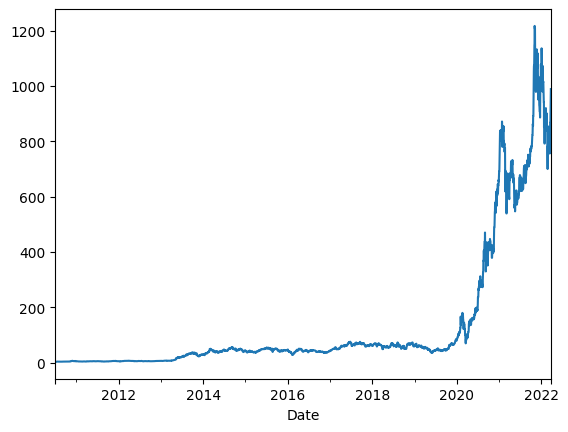

In [3]:
index = df[df["Low"] < 0].index 
df = df.drop(index)
df["Low"].plot()

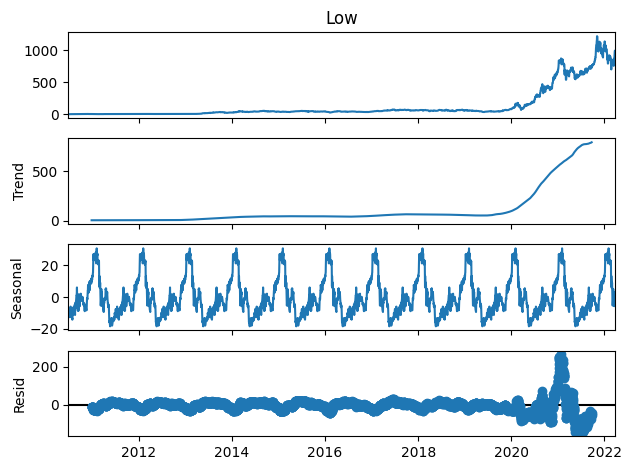

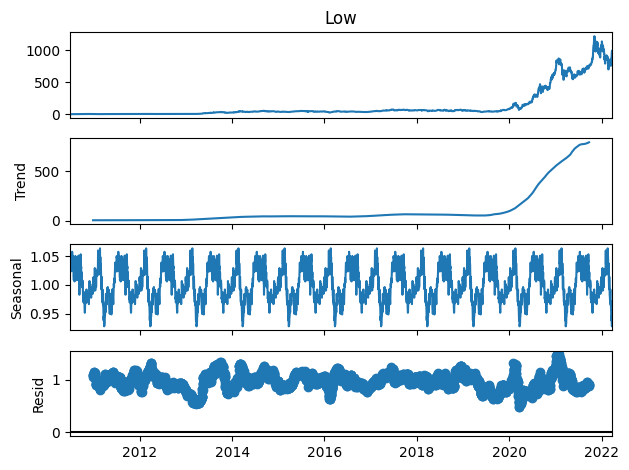

In [4]:
from statsmodels.tsa.seasonal import seasonal_decompose

result_add = seasonal_decompose(df["Low"], period=365, model="additive")
result_mul = seasonal_decompose(df["Low"], period=365, model="multiplicative")
result_add.plot()
result_mul.plot()
plt.show()

MOVING AVERAGE

In [5]:
mvg = df["Low"].reset_index()
mvg["Moving_avg"] = mvg["Low"].rolling(window=7).mean()
mvg[["Low", "Moving_avg"]].head(10)

,Low,Moving_avg
0,3.508,NaN
1,4.660,NaN
2,4.054,NaN
3,3.742,NaN
4,3.742,NaN
5,3.742,NaN
6,3.742,3.884286
7,3.166,3.835429
8,2.996,3.597714
9,3.114,3.463429


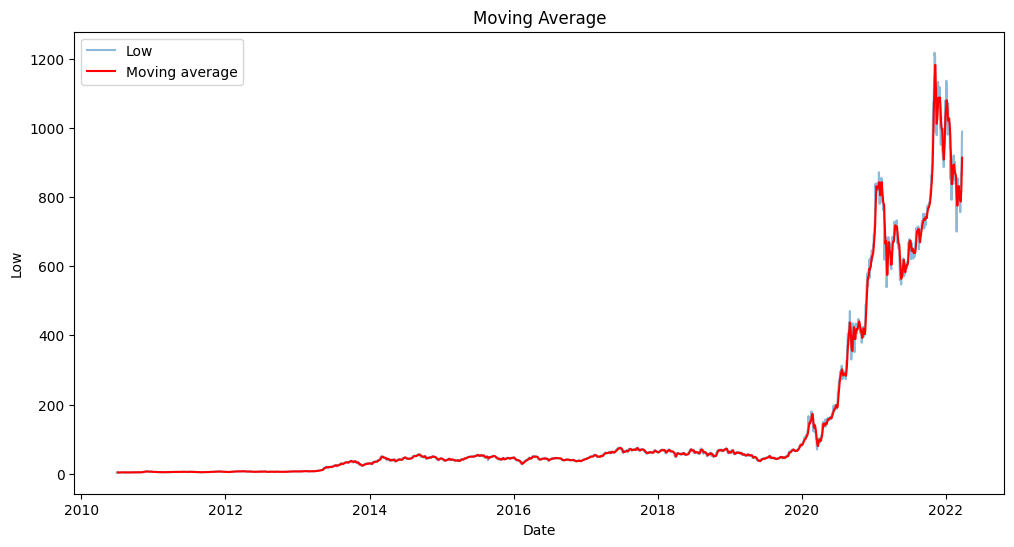

In [6]:
plt.figure(figsize=(12, 6))
sns.lineplot(x = df["Low"].index, y = df["Low"].values, label='Low', alpha=0.5)
sns.lineplot(x = mvg["Date"], y = mvg["Moving_avg"], label='Moving average', color='red')
plt.title('Moving Average')
plt.xlabel('Date')
plt.ylabel('Low')
plt.legend()
plt.show()

EXPONENTIAL SMOOTHING

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.holtwinters import ExponentialSmoothing

single = ExponentialSmoothing(df["Low"].values, trend=None, seasonal=None).fit()
double = ExponentialSmoothing(df["Low"].values, trend='mul', seasonal=None).fit()
triple = ExponentialSmoothing(df["Low"].values, trend='mul', seasonal="mul", seasonal_periods=365).fit()

exponential = pd.DataFrame({
    "Single" : single.fittedvalues,
    "Double" : double.fittedvalues,
    "Triple" : triple.fittedvalues,
})

exponential.head()

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/statsmodels/tsa/holtwinters/model.py:84: RuntimeWarning: overflow encountered in matmul
  return err.T @ err


,Single,Double,Triple
0,4.301067,4.182073,5.443034
1,3.511965,3.401252,3.461539
2,4.654260,4.547088,4.695962
3,4.057001,3.953399,4.103209
4,3.743575,3.643355,3.777625


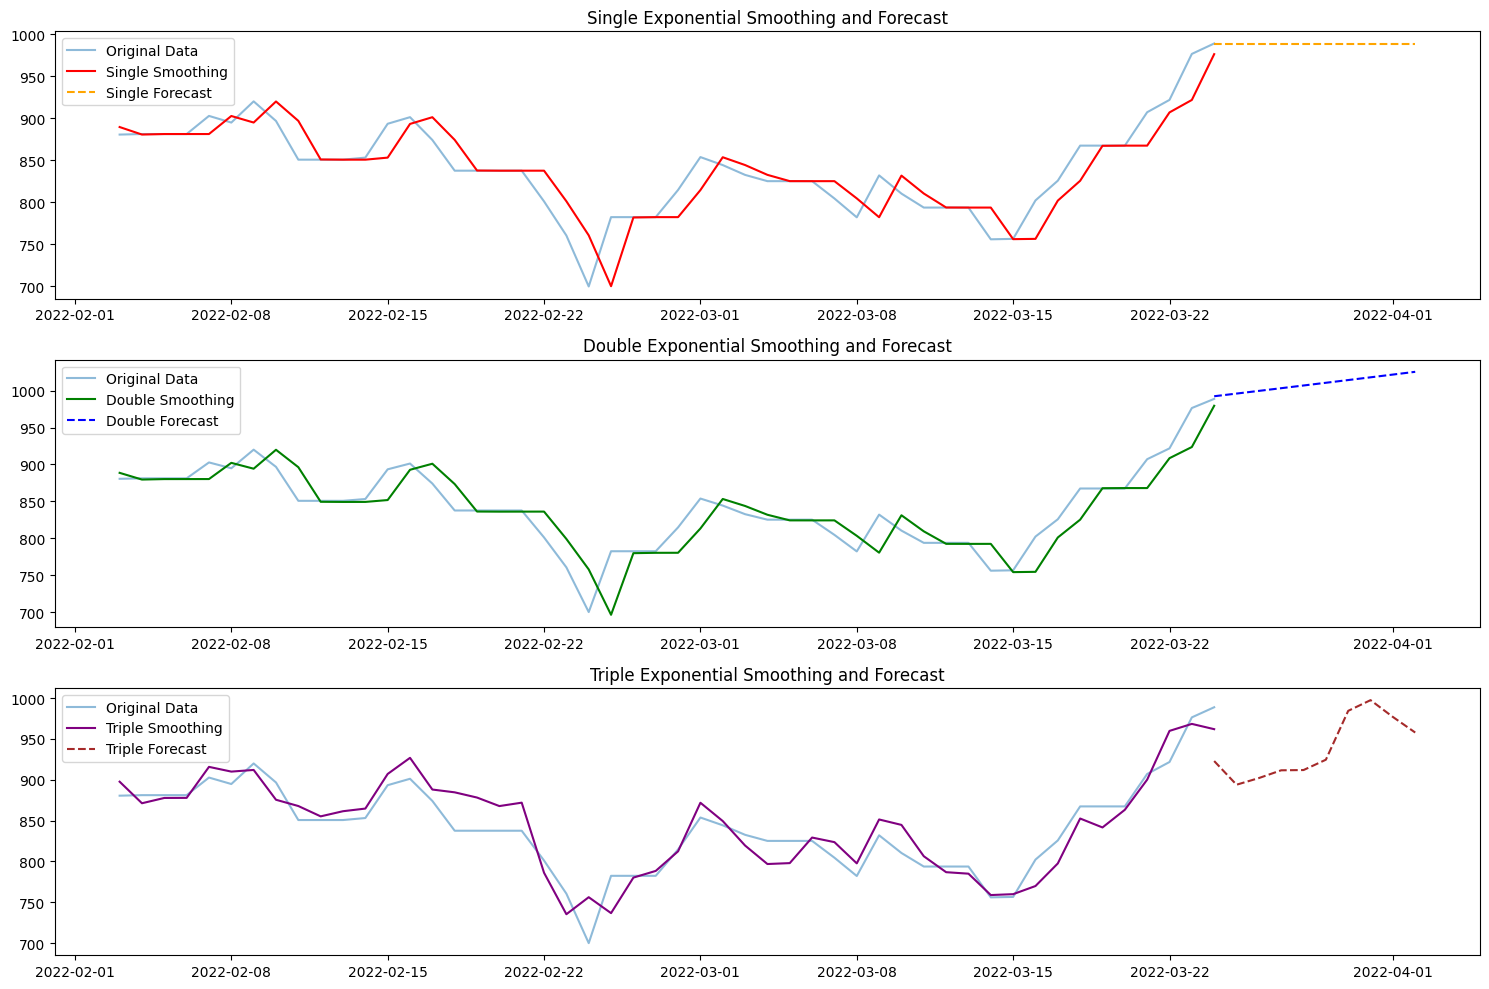

In [8]:
day = 10
single_forecast = single.forecast(steps=day)
double_forecast = double.forecast(steps=day)
triple_forecast = triple.forecast(steps=day)

data = 50  
group_tail = df["Low"].tail(data)
index_future = pd.date_range(start=df["Low"].index[-1], periods=day, freq='D')

plt.figure(figsize=(15, 10))

# Plot Single Exponential Smoothing
plt.subplot(3, 1, 1)
plt.plot(group_tail.index, group_tail.values, label="Original Data", alpha=0.5)
plt.plot(group_tail.index, single.fittedvalues[-data:], label="Single Smoothing", color='red')
plt.plot(index_future, single_forecast, label="Single Forecast", linestyle="--", color='orange')
plt.title("Single Exponential Smoothing and Forecast")
plt.legend()

# Plot Double Exponential Smoothing
plt.subplot(3, 1, 2)
plt.plot(group_tail.index, group_tail.values, label="Original Data", alpha=0.5)
plt.plot(group_tail.index, double.fittedvalues[-data:], label="Double Smoothing", color='green')
plt.plot(index_future, double_forecast, label="Double Forecast", linestyle="--", color='blue')
plt.title("Double Exponential Smoothing and Forecast")
plt.legend()

# Plot Triple Exponential Smoothing
plt.subplot(3, 1, 3)
plt.plot(group_tail.index, group_tail.values, label="Original Data", alpha=0.5)
plt.plot(group_tail.index, triple.fittedvalues[-data:], label="Triple Smoothing", color='purple')
plt.plot(index_future, triple_forecast, label="Triple Forecast", linestyle="--", color='brown')
plt.title("Triple Exponential Smoothing and Forecast")
plt.legend()

plt.tight_layout()
plt.show()

ARIMA

In [45]:
from pmdarima import auto_arima
from statsmodels.tsa.arima.model import ARIMA

In [46]:
group_data = df[["Low", "High"]]
group_data.head()

,Low,High
Date,,
2010-06-29,3.508,5.000
2010-06-30,4.660,6.084
2010-07-01,4.054,5.184
2010-07-02,3.742,4.620
2010-07-03,3.742,4.620


In [47]:
from statsmodels.tsa.stattools import adfuller

adf_low = adfuller(group_data["Low"])
adf_high = adfuller(group_data["High"])
print('p-value low:', adf_low[1])
print('p-value high:', adf_high[1])

p-value low: 0.9971326711728342
p-value high: 0.9962582700895541


In [ ]:
len_train = int(len(group_data) * 0.8)
train = group_data[:len_train]
test = group_data[len_train:]

<Axes: xlabel='Date'>

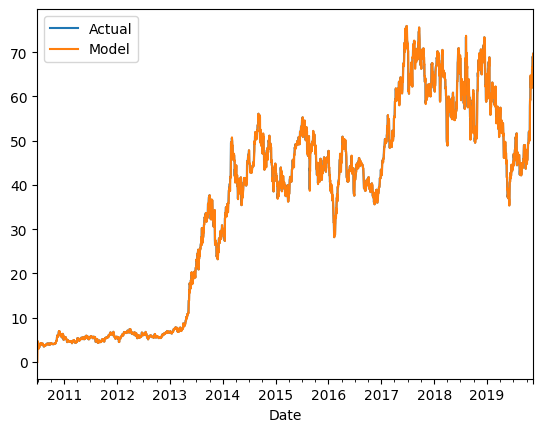

In [49]:
auto = auto_arima(train["Low"], 
                  trace=False,
                  suppress_warnings=True, 
                  error_action="ignore", 
                  stepwise = True)

p, d, q = auto.order

model = ARIMA(train["Low"], order=(p, d, q))
model_fit = model.fit()

start = 0
end = len(train) - 1

prediction = model_fit.predict(start, end)

train["Low"].plot(label = "Actual", legend = True)
prediction.plot(label = "Model", legend = True)

<Axes: xlabel='Date'>

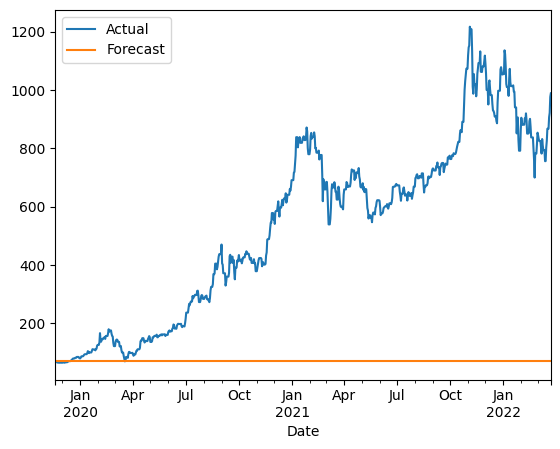

In [50]:
forecast = model_fit.forecast(len(test))
test["Low"].plot(label = "Actual", legend = True)
forecast.plot(label = "Forecast", legend = True)

SARIMA

RUNNING THE L-BFGS-B CODE

           * * *

Machine precision = 2.220D-16
 N =            2     M =           10

At X0         0 variables are exactly at the bounds

At iterate    0    f=  1.40015D+00    |proj g|=  6.25351D-04

           * * *

Tit   = total number of iterations
Tnf   = total number of function evaluations
Tnint = total number of segments explored during Cauchy searches
Skip  = number of BFGS updates skipped
Nact  = number of active bounds at final generalized Cauchy point
Projg = norm of the final projected gradient
F     = final function value

           * * *

   N    Tit     Tnf  Tnint  Skip  Nact     Projg        F
    2      2      8      1     0     0   2.202D-05   1.400D+00
  F =   1.4001530571351577     

CONVERGENCE: REL_REDUCTION_OF_F_<=_FACTR*EPSMCH             


 This problem is unconstrained.


<Axes: xlabel='Date'>

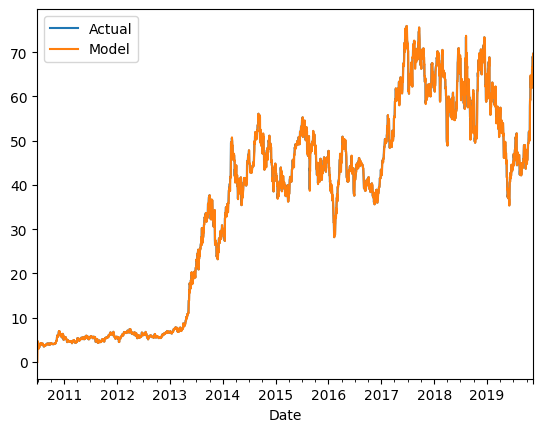

In [51]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

auto = auto_arima(
    train["Low"],
    seasonal=True,              
    m=52,                        
    trace=False,
    suppress_warnings=True,
    error_action="ignore",
    stepwise=True
)

p, d, q = auto.order
P, D, Q, s = auto.seasonal_order

model = SARIMAX(
    train['Low'],
    order=(p, d, q),
    seasonal_order=(P, D, Q, s),
)
model_fit = model.fit()

predictions = model_fit.predict(start=0, end=len(train) - 1)

train["Low"].plot(label = "Actual", legend = True)
predictions.plot(label = "Model", legend = True)

<Axes: xlabel='Date'>

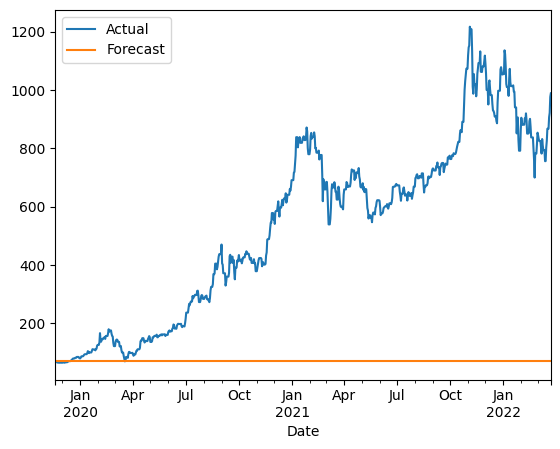

In [52]:
forecast = model_fit.forecast(steps = len(test))

test["Low"].plot(label = "Actual", legend = True)
forecast.plot(label = "Forecast", legend = True)

SARIMAX

 This problem is unconstrained.


RUNNING THE L-BFGS-B CODE

           * * *

Machine precision = 2.220D-16
 N =            3     M =           10

At X0         0 variables are exactly at the bounds

At iterate    0    f=  9.13476D-01    |proj g|=  1.70089D-01

At iterate    5    f=  9.04051D-01    |proj g|=  2.96600D-03

           * * *

Tit   = total number of iterations
Tnf   = total number of function evaluations
Tnint = total number of segments explored during Cauchy searches
Skip  = number of BFGS updates skipped
Nact  = number of active bounds at final generalized Cauchy point
Projg = norm of the final projected gradient
F     = final function value

           * * *

   N    Tit     Tnf  Tnint  Skip  Nact     Projg        F
    3      8     11      1     0     0   1.108D-06   9.040D-01
  F =  0.90404874663550139     

CONVERGENCE: NORM_OF_PROJECTED_GRADIENT_<=_PGTOL            


<Axes: xlabel='Date'>

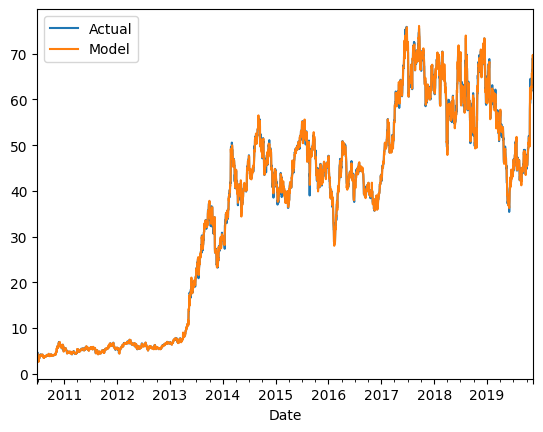

In [ ]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

auto = auto_arima(
    train["Low"],
    exogenous=train['High'],  
    seasonal=True,              
    m=52,                        
    trace=False,
    suppress_warnings=True,
    error_action="ignore",
    stepwise=True
)

p, d, q = auto.order
P, D, Q, s = auto.seasonal_order

model = SARIMAX(
    train['Low'],
    exog=train['High'],
    order=(p, d, q),
    seasonal_order=(P, D, Q, s),
)
model_fit = model.fit()

predictions = model_fit.predict(start=0, end=len(train) - 1, exog=train["Low"])

train["Low"].plot(label = "Actual", legend = True)
predictions.plot(label = "Model", legend = True)

<Axes: xlabel='Date'>

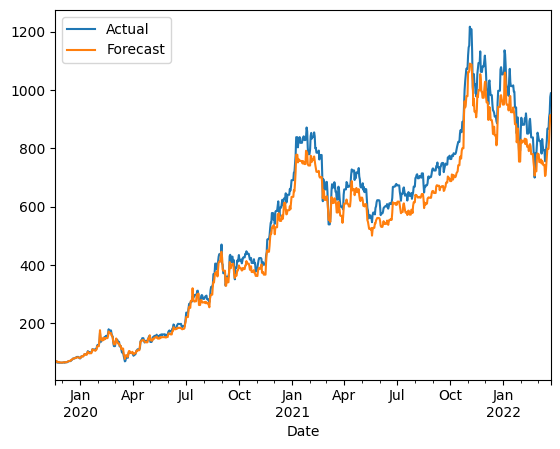

In [57]:
forecast = model_fit.forecast(steps = len(test), exog = test["High"])
test["Low"].plot(label = "Actual", legend = True)
forecast.plot(label = "Forecast", legend = True)